In [1]:
# notebook to perform updated COSMIC analysis with inclusion of indels for revision
# 081826

In [1]:
# import packages
import pandas as pd
import numpy as np
from scipy import stats
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches
from collections import Counter
pd.options.mode.chained_assignment = None
from matplotlib.lines import Line2D

In [2]:
# define function to calculate odds ratios
# does not account for activity - filter for activity if desired
# not set up for multiple variates, pre-filter DF for that
# eg filter full DF for only 250bp promoters and then use recurrence to compare recurrent v unique promoter variants
def oddsR_calculator(df, column_of_interest, emvar_col):
    pos = df[column_of_interest] == 1
    
    a = df.loc[pos, emvar_col].sum()       # positive + emvar
    b = pos.sum() - a                       # positive + non-emvar
    c = df.loc[~pos, emvar_col].sum()      # negative + emvar
    d = (~pos).sum() - c                    # negative + non-emvar

    table = np.array([[a, b], [c, d]])

    oddsr, pval = stats.fisher_exact(table)
    ci = stats.contingency.odds_ratio(table).confidence_interval(0.95)

    odds_df = pd.DataFrame([{
        'label': column_of_interest,
        'OddsR': oddsr,
        'p_val': pval,
        'round_p': np.round(pval, 4),
        'lowerCI': ci[0],
        'upperCI': ci[1],
        'n_pos_emvar': a,
        'n_pos_nonemVar': b,
        'n_neg_emvar': c,
        'n_neg_nonemVar': d,
    }])

    return odds_df, table

In [3]:
def oddsR_feature_by_skew_bin_all(preds_df, list_of_bins, feature, feature_ann):
    df = preds_df.copy()
    df['mean_skew_bin'] = pd.cut(df['mean_skew'], list_of_bins)

    # Precompute totals once
    total_with_feature = df[feature].sum()
    total_without_feature = len(df) - total_with_feature

    results = []

    for bin_label, bin_df in df.groupby('mean_skew_bin', observed=True):
        a = bin_df[feature].sum()           # in bin, has feature
        b = len(bin_df) - a                  # in bin, no feature
        c = total_with_feature - a           # not in bin, has feature
        d = total_without_feature - b        # not in bin, no feature

        table = np.array([[a, b], [c, d]])

        oddsr, pval = stats.fisher_exact(table)
        ci = stats.contingency.odds_ratio(table).confidence_interval(0.95)

        results.append({
            'Feature': feature_ann,
            'OddsR': oddsr,
            'p_val': pval,
            'round_p': np.round(pval, 4),
            'lowerCI': ci[0],
            'upperCI': ci[1],
            'Bin': bin_label,
            'n_bin': len(bin_df),
            'n_feature_in_bin': a,
        })

    return pd.DataFrame(results).sort_values('Bin').reset_index(drop=True)

In [4]:
def oddsR_emvar_by_act_bin_max(preds_df, skew_threshold=0.5):
    df = preds_df.copy()

    # Classify emvar once on the full df
    df['is_emvar'] = (df['max_skew'].abs() > skew_threshold).astype(int)

    # Split once
    recurrent = df[df['recurrent'] == 1]
    unique = df[df['recurrent'] != 1]

    # Precompute totals
    total_recurrent = len(recurrent)
    total_unique = len(unique)

    results = []

    for bin_label in df['max_act_bin'].dropna().unique():
        bin_r = recurrent[recurrent['max_act_bin'] == bin_label]
        bin_u = unique[unique['max_act_bin'] == bin_label]

        a = bin_r['is_emvar'].sum()          # recurrent emvars in bin
        c = total_recurrent - a              # recurrent non-emvars (all other bins)
        b = bin_u['is_emvar'].sum()          # unique emvars in bin
        d = total_unique - b                 # unique non-emvars (all other bins)

        table = np.array([[a, b], [c, d]])
        #print(bin_label)
        #display(table)
        oddsr, pval = stats.fisher_exact(table)
        ci = stats.contingency.odds_ratio(table).confidence_interval(0.95)
        
        results.append({
            'feature': 'emVar',
            'oddsR': oddsr,
            'p_val': pval,
            'lowerCI': ci[0],
            'upperCI': ci[1],
            'Bin': bin_label,
            'label': str(bin_label),
            'n_recurrent_emvars': a,
            'n_unique_emvars': b,
            'n_recurrent_in_bin': len(bin_r),
            'n_unique_in_bin': len(bin_u),
        })

    return pd.DataFrame(results).sort_values('Bin').reset_index(drop=True)

In [5]:
# define function to assign max skew and activity bin
def reformat_df4act_bin (df):
    # get cell type of max skew
    max_skew_cell = []
    max_skew_l2fc = []
    for k_skew, h_skew, s_skew in zip(df['k562_skew_pred'],
                                      df['hepg2_skew_pred'],
                                      df['sknsh_skew_pred']):
        skew_list = [k_skew, h_skew, s_skew]
        max_skew = max([k_skew, h_skew, s_skew], key=abs)
        if skew_list[0] == max_skew:
            max_skew_cell.append('k562')
            max_skew_l2fc.append(max_skew)
        elif skew_list[1] == max_skew:
            max_skew_cell.append('hepg2')
            max_skew_l2fc.append(max_skew)
        elif skew_list[2] == max_skew:
            max_skew_cell.append('sknsh')
            max_skew_l2fc.append(max_skew)
    df['max_skew_cell'] = max_skew_cell
    # get matching activity bin
    k_act_bin = df['k562_act_bin'].tolist()
    h_act_bin = df['hepg2_act_bin'].tolist()
    s_act_bin = df['sknsh_act_bin'].tolist()
    act_bin = []
    for i,j in tqdm(zip(range(len(df)),
                   df['max_skew_cell'])):
        if j == 'k562':
            act_bin.append(k_act_bin[i])
        elif j == 'hepg2':
            act_bin.append(h_act_bin[i])
        elif j == 'sknsh':
            act_bin.append(s_act_bin[i])
    df['max_act_bin'] = act_bin
    # return skew of max cell type
    df['max_skew'] = max_skew_l2fc
    return df

In [6]:
# open annotated COSMIC predictions
cosmic_preds = pd.read_csv('../processed_data/all.cosmic.v98.autosome.with.10bp.indels.annotated.017.081626.tsv', sep = '\t', low_memory=False)
# add activity bins
# annotate activity ranges
cosmic_preds['mean_ref_bin'] = pd.cut(cosmic_preds['mean_ref_act'], [float('-inf'), 1, 2, 3, 4, 5, float('inf')])
cosmic_preds['k562_act_bin'] = pd.cut(cosmic_preds['k562_max_act'], [float('-inf'), 1, 2, 3, 4, 5, float('inf')])
cosmic_preds['hepg2_act_bin'] = pd.cut(cosmic_preds['hepg2_max_act'], [float('-inf'), 1, 2, 3, 4, 5, float('inf')])
cosmic_preds['sknsh_act_bin'] = pd.cut(cosmic_preds['sknsh_max_act'], [float('-inf'), 1, 2, 3, 4, 5, float('inf')])

In [7]:
# filter for only non-coding + synonymous variants
cosmic_preds = cosmic_preds[(cosmic_preds['vep_coding_related'] == 0) | (cosmic_preds['vep_most_severe'] == 'synonymous_variant')]

In [8]:
len(cosmic_preds)

2190594

In [9]:
# count number of recurrent emvars
# in promoters. no exon filter
n_recurrent_pro_emvars = len(cosmic_preds[(cosmic_preds['emvar_any'] == 1) &
                                          (cosmic_preds['recurrent'] == 1) &
                                          (cosmic_preds['250bp_pro'] == 1)])
print(f'The number of recurrent promoter emVars is {n_recurrent_pro_emvars}')
# out of promoters, no exon filter
n_recurrent_emvars_noPro = len(cosmic_preds[(cosmic_preds['emvar_any'] == 1) &
                                            (cosmic_preds['recurrent'] == 1) &
                                            (cosmic_preds['250bp_pro'] == 0)])
print(f'The number of recurrent non-promoter emVars is {n_recurrent_emvars_noPro}')

The number of recurrent promoter emVars is 113
The number of recurrent non-promoter emVars is 1279


In [10]:
# calculate odds ratios for generating plot from figure 2D
# odds ratio a variant is an emVar in the selected bin vs. non-emVar
# recurrent vs. unique variant
recurrent_OR_df, recurrent_2x2 = oddsR_calculator(cosmic_preds,
                                                  'recurrent',
                                                  'emvar_any')
# 250bp promoter vs. non-promoter
twoFifty_OR_df, twoFifty_2x2 = oddsR_calculator(cosmic_preds,
                                                '250bp_pro',
                                                'emvar_any')
# cnc promoter
cnc_OR_df, cnc_2x2 = oddsR_calculator(cosmic_preds,
                                      'cnc_pro',
                                      'emvar_any')
# recurrent 250bp promoter
recurrent250_OR_df, recurrent250_2x2 = oddsR_calculator(cosmic_preds,
                                                        'recurrent_250bp_pro',
                                                        'emvar_any')
# recurrent cnc promoter
recurrentCNC_OR_df, recurrentCNC_2x2 = oddsR_calculator(cosmic_preds,
                                                        'recurrent_cnc_pro',
                                                        'emvar_any')
# concatenate all together for plotting
cat_odds_or = pd.concat([recurrent_OR_df,
                         twoFifty_OR_df,
                         cnc_OR_df,
                         recurrent250_OR_df,
                         recurrentCNC_OR_df])
# add a column to concatenated df with label for y axis on plot below
cat_odds_or['plot_labs'] = ['Recurrent',
                            '250bp Promoter',
                            'CNC Promoter',
                            'Recurrent Promoter',
                            'Recurrent CNC Promoter']
# define a color palette for recurrence, etc.
feature_palette = {'recurrent' : '#1F271B',
                   'Recurrent' : '#1F271B',
                   '250bp_promoter' : "#F15B60",
                   '250bp Promoter' : "#F15B60",
                   '250_pro_seqlet' : 'dodgerblue',
                   '250bp Promoter Seqlet' : 'dodgerblue',
                   'cnc_database_250bp_promoter' : "#00A14B",
                   'CNC Promoter' : "#00A14B",
                   'recurrent_250bp_promoter' : "#F26522",
                   'Recurrent Promoter' : "#F26522",
                   'recurrent_cnc_promoter' : "#6A4D94",
                   'Recurrent CNC Promoter' : "#6A4D94"}

In [11]:
cat_odds_or

,label,OddsR,p_val,round_p,lowerCI,upperCI,n_pos_emvar,n_pos_nonemVar,n_neg_emvar,n_neg_nonemVar,plot_labs
0,recurrent,1.336959,6.513069e-24,0.0,1.265646,1.411360,1392,52915,41223,2095064,Recurrent
0,250bp_pro,6.612525,1.263515e-293,0.0,6.091263,7.169385,677,5231,41938,2142748,250bp Promoter
0,cnc_pro,10.203924,5.136338e-34,0.0,7.492114,13.679005,55,272,42560,2147707,CNC Promoter
0,recurrent_250bp_pro,15.773110,2.256201e-85,0.0,12.652003,19.538588,113,362,42502,2147617,Recurrent Promoter
0,recurrent_cnc_pro,17.917507,7.224303e-23,0.0,11.098993,28.129890,27,76,42588,2147903,Recurrent CNC Promoter


In [12]:
# plot TERT promoter mutations
# -124 COSV57196518
# -146 COSV57196531
# filter full cosmic predictions for TERT promoter mutations
minus124_skew = cosmic_preds[cosmic_preds['id'] == 'COSV57196518']['mean_skew'].tolist()[0]
minus146_skew = cosmic_preds[cosmic_preds['id'] == 'COSV57196531']['mean_skew'].tolist()[0]
# build the DF for plotting
tert_pro_vars2plot = pd.DataFrame({
    'Skew' : [minus124_skew, minus146_skew],
    'TERT Promoter Mutation' : ['-124 C>T', '-146 C>T']
})

/tmp/ipykernel_2458773/3824673798.py:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.pointplot(


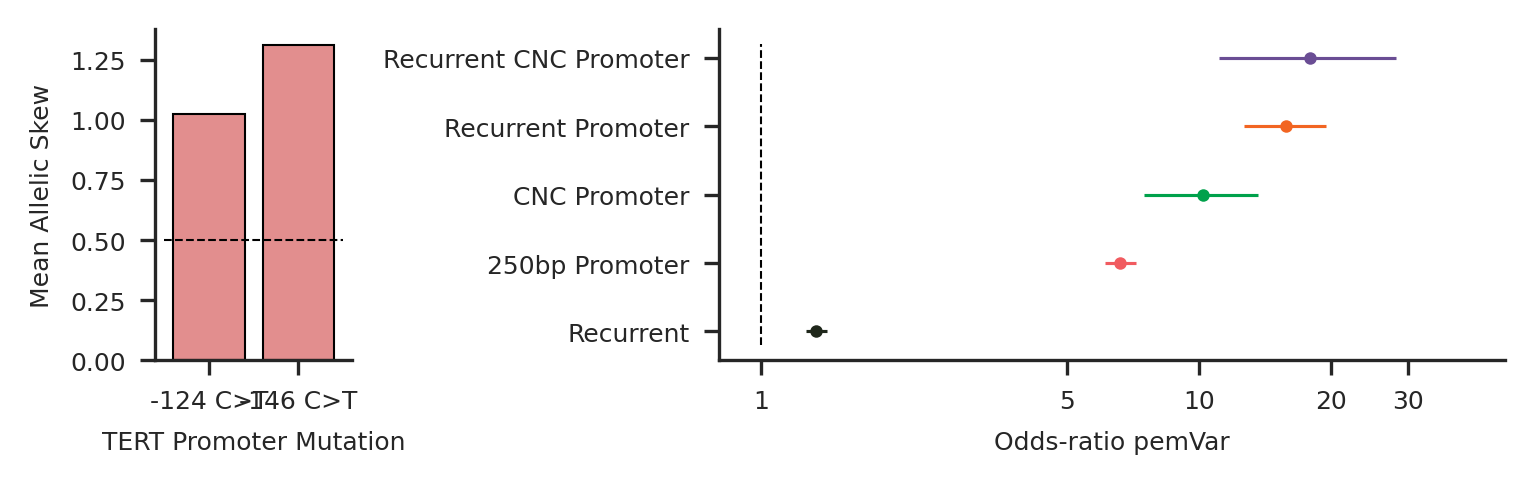

In [13]:
CM = 1 / 2.54
f = plt.figure(figsize=(5, 1.5), dpi=300, layout='constrained')
plt.rcParams.update({
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "font.size": 6, "axes.labelsize": 6, "axes.titlesize": 6,
    "xtick.labelsize": 6, "ytick.labelsize": 6,
})
gs = f.add_gridspec(1,2, width_ratios = [0.2, 0.8])
# add tert promoter skew
with sns.axes_style("ticks", {"axes.spines.right": False,
                        "axes.spines.top": False}):
    ax_01 = f.add_subplot(gs[0,0])
    sns.barplot(data=tert_pro_vars2plot,
            x='TERT Promoter Mutation',
            y='Skew',
            color='lightcoral',
            edgecolor='k',
            linewidth=0.5)
    xmin, xmax = ax_01.get_xlim()
    plt.hlines(y=.5, xmin=xmin, xmax=xmax, color='k', linewidth=0.5, linestyle='dashed')
    plt.ylabel('Mean Allelic Skew')
# add overall enrichments
with sns.axes_style("ticks", {"axes.spines.right": False,
                        "axes.spines.top": False}):
    ax_03 = f.add_subplot(gs[0, 1])
    ax_03.set_xscale('log')
    ax_03.minorticks_off()
    sns.pointplot(
        data=cat_odds_or.sort_values(by='OddsR', ascending = False), x="OddsR", y="plot_labs",
        palette=feature_palette, linestyle="none", marker=".", markersize=6, linewidth=0
)
    plt.ylabel('')
    for lower, upper, lab, n_emVar, n_nonemVar in zip(cat_odds_or['lowerCI'],
                                                      cat_odds_or['upperCI'],
                                                      cat_odds_or['plot_labs'],
                                                      cat_odds_or['n_pos_emvar'],
                                                      cat_odds_or['n_pos_nonemVar']):
        plt.hlines(xmin=lower, xmax=upper, y=lab, color=feature_palette.get(lab), linewidth=0.75)

    ymin, ymax = ax_03.get_ylim()
    plt.vlines(x=1, ymin=ymin, ymax=ymax, color='k', linewidth=0.5, linestyle='dashed')
    plt.xlabel('Odds-ratio pemVar')
    plt.xticks([1,5,10,20, 30], ['1','5','10', '20', '30'])
    plt.xlim(.8, 50)

#plt.savefig('../figures/tert_promoter_muts_and_emvar_enrichments_rev2.pdf')

In [14]:
# calculate oddsR by mean skew bin for each promoter feature
# recurrent
recurrent_oddsR_by_bin = oddsR_feature_by_skew_bin_all(cosmic_preds,
                                                       [float('-inf'), -1, -.5, -.2, -.05, .05, .2, .5, 1, float('inf')],
                                                       'recurrent',
                                                       'Recurrent')
recurrent_oddsR_by_bin['label'] = [str(i) for i in recurrent_oddsR_by_bin['Bin']]
# recurrent non-promoter
recurrent_oddsR_by_bin_no_pro = oddsR_feature_by_skew_bin_all(cosmic_preds[cosmic_preds['250bp_pro'] == 0],
                                                              [float('-inf'), -1, -.5, -.2, -.05, .05, .2, .5, 1, float('inf')],
                                                              'recurrent',
                                                              'Recurrent: Non-Promoter')
recurrent_oddsR_by_bin_no_pro['label'] = [str(i) for i in recurrent_oddsR_by_bin_no_pro['Bin']]
# recurrent in DHS
recurrent_oddsR_by_bin_no_pro_in_dhs = oddsR_feature_by_skew_bin_all(cosmic_preds[(cosmic_preds['250bp_pro'] == 0) &
                                                                                  (cosmic_preds['dhs'] == 1)],
                                                                     [float('-inf'), -1, -.5, -.2, -.05, .05, .2, .5, 1, float('inf')],
                                                                     'recurrent',
                                                                     'Recurrent: In DHS')
recurrent_oddsR_by_bin_no_pro_in_dhs['label'] = [str(i) for i in recurrent_oddsR_by_bin_no_pro_in_dhs['Bin']]
# 250bp promoter
twoFifty_oddsR_by_bin = oddsR_feature_by_skew_bin_all(cosmic_preds,
                                                      [float('-inf'), -1, -.5, -.2, -.05, .05, .2, .5, 1, float('inf')],
                                                      '250bp_pro',
                                                      '250bp_pro')
twoFifty_oddsR_by_bin['label'] = [str(i) for i in twoFifty_oddsR_by_bin['Bin']]
# # CNC promoter
cnc_pro_oddsR_by_bin =  oddsR_feature_by_skew_bin_all(cosmic_preds,
                                                      [float('-inf'), -1, -.5, -.2, -.05, .05, .2, .5, 1, float('inf')],
                                                      'cnc_pro',
                                                      'CNC Promoter')
cnc_pro_oddsR_by_bin['label'] = [str(i) for i in cnc_pro_oddsR_by_bin['Bin']]
# # Promoter Recurrent
recurrent_promoter_OR_by_bin = oddsR_feature_by_skew_bin_all(cosmic_preds,
                                                             [float('-inf'), -1, -.5, -.2, -.05, .05, .2, .5, 1, float('inf')],
                                                             'recurrent_250bp_pro',
                                                             'Recurrent Promoter')
recurrent_promoter_OR_by_bin['label'] = [str(i) for i in recurrent_promoter_OR_by_bin['Bin']]
# # CNC Recurrent
recurrent_cnc_promoter_OR_by_bin = oddsR_feature_by_skew_bin_all(cosmic_preds,
                                                                 [float('-inf'), -1, -.5, -.2, -.05, .05, .2, .5, 1, float('inf')],
                                                                 'recurrent_cnc_pro',
                                                                 'Recurrent CNC Promoter')
recurrent_cnc_promoter_OR_by_bin['label'] = [str(i) for i in recurrent_cnc_promoter_OR_by_bin['Bin']]

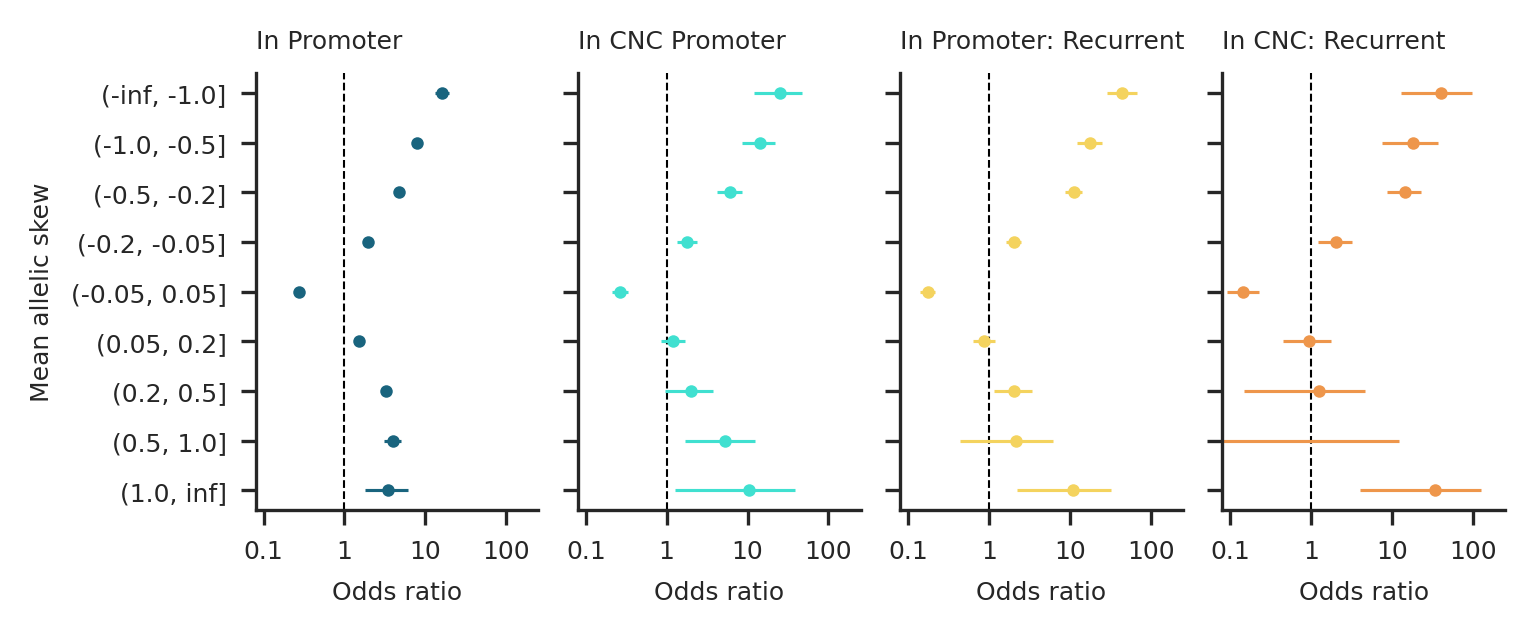

In [15]:
sns.set_style("ticks", {"axes.spines.right": False, "axes.spines.top": False})
plt.rcParams.update({
    "pdf.fonttype": 42, "ps.fonttype": 42,
    "font.size": 6, "axes.labelsize": 6, "axes.titlesize": 6,
    "xtick.labelsize": 6, "ytick.labelsize": 6,
})

panels = [
    (twoFifty_oddsR_by_bin,            "#19647E",   "In Promoter"),
    (cnc_pro_oddsR_by_bin,             "turquoise", "In CNC Promoter"),
    (recurrent_promoter_OR_by_bin,     "#F4D35E",   "In Promoter: Recurrent"),
    (recurrent_cnc_promoter_OR_by_bin, "#EE964B",   "In CNC: Recurrent"),
]
xticks = [0.1, 1, 10, 100]

f = plt.figure(figsize=(5, 2), dpi=300, layout="constrained")
gs = f.add_gridspec(1, 4)

for i, (df, col, title) in enumerate(panels):
    ax = f.add_subplot(gs[0, i])
    ax.set_xscale("log")
    sns.pointplot(data=df, x="OddsR", y="label", color=col, linestyle="none",
                  marker=".", markersize=6, errorbar=None, ax=ax, linewidth=0)
    for lower, upper, lab in zip(df["lowerCI"], df["upperCI"], df["label"]):
        ax.hlines(xmin=lower, xmax=upper, y=lab, color=col, linewidth=0.75)
    ax.axvline(1, color="k", linewidth=0.5, linestyle="dashed", zorder=0)

    ax.minorticks_off()
    ax.set_xticks(xticks, [f"{t:g}" for t in xticks])   # add labelrotation=-90 if you keep rotating
    ax.set_xlim(0.08, 250)                               # same range in every panel
    ax.set_xlabel("Odds ratio")
    ax.set_title(title, loc="left")

    if i == 0:
        ax.set_ylabel("Mean allelic skew")
    else:
        ax.set_ylabel("")
        ax.tick_params(axis="y", labelleft=False)        # ticks kept, labels hidden
#plt.savefig('../figures/promoter_skew_bin_row_all_rev3_updated.pdf', bbox_inches='tight')

In [16]:
# calculate the emVar rate by activity bin
cosmic_preds4act_bin = reformat_df4act_bin(cosmic_preds)
# calculate oddsR an emVar is recurrent by activity bin
recurrent_emvar_or_by_act = oddsR_emvar_by_act_bin_max(cosmic_preds4act_bin)
# calculate oddsR an emVar is recurrent by activity bin - no promoters
recurrent_emvar_or_by_act_no_pro = oddsR_emvar_by_act_bin_max(cosmic_preds4act_bin[cosmic_preds4act_bin['250bp_pro'] == 0])
# calculate oddsR an emVar is recurrent by activity bin - no promoters, in DHS
recurrent_emvar_or_by_act_no_pro_in_dhs = oddsR_emvar_by_act_bin_max(cosmic_preds4act_bin[(cosmic_preds4act_bin['250bp_pro'] == 0) &
                                                                                          (cosmic_preds4act_bin['dhs'] == 1)])
# calculate oddsR an emVar is recurrent by activity bin - in promoter
recurrent_emvar_or_by_act_250_pro = oddsR_emvar_by_act_bin_max(cosmic_preds4act_bin[cosmic_preds4act_bin['250bp_pro'] == 1])

2190594it [00:00, 2681450.57it/s]


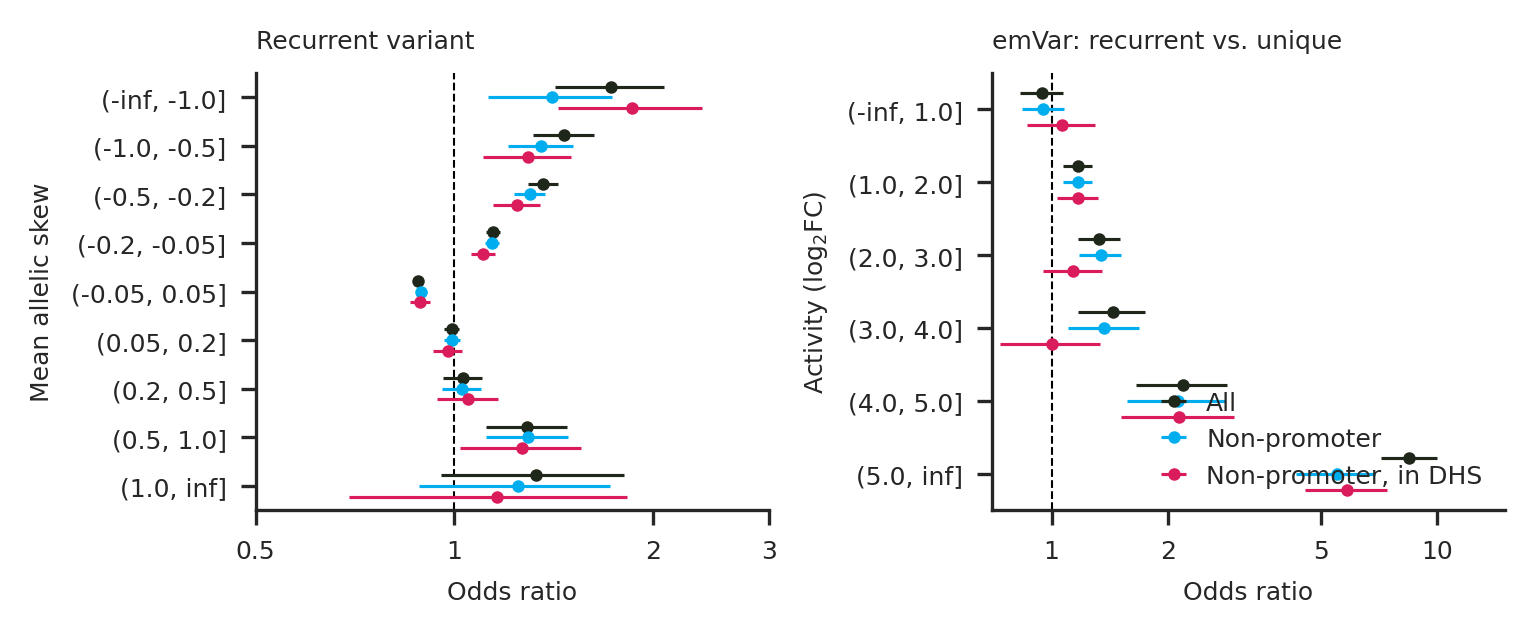

In [17]:
def dodged_forest(ax, groups, xcol, ycol, order, step=0.22):
    """groups: list of (df, color, name); plotted top-to-bottom within each bin."""
    pos = {lab: i for i, lab in enumerate(order)}
    n = len(groups)
    for k, (df, color, name) in enumerate(groups):
        y = df[ycol].map(pos) + (k - (n - 1) / 2) * step
        x = df[xcol]
        ax.errorbar(x, y, xerr=[x - df["lowerCI"], df["upperCI"] - x],
                    fmt=".", ms=6, mew=0, color=color, ecolor=color,
                    elinewidth=0.75, capsize=0, label=name, zorder=3)
    ax.axvline(1, color="k", lw=0.5, ls="--", zorder=0)
    ax.set_xscale("log")
    ax.minorticks_off()
    ax.set_yticks(range(len(order)), order)
    ax.set_ylim(len(order) - 0.5, -0.5)          # first bin at top

colors = {"All": "#1F271B", "Non-promoter": "#00AEEF", "Non-promoter, in DHS": "#DA1C5C"}

f = plt.figure(figsize=(5, 2), dpi=300, layout="constrained")
gs = f.add_gridspec(1, 2)

# --- F: recurrent variant OR by skew bin ---
ax0 = f.add_subplot(gs[0, 0])
dodged_forest(ax0,
    [(recurrent_oddsR_by_bin,               colors["All"],                  "All"),
     (recurrent_oddsR_by_bin_no_pro,        colors["Non-promoter"],         "Non-promoter"),
     (recurrent_oddsR_by_bin_no_pro_in_dhs, colors["Non-promoter, in DHS"], "Non-promoter, in DHS")],
    xcol="OddsR", ycol="label", order=recurrent_oddsR_by_bin["label"].tolist())
ax0.set_xlim(0.5, 3)
ax0.set_xticks([0.5, 1, 2, 3], ["0.5", "1", "2", "3"])
ax0.set(xlabel="Odds ratio", ylabel="Mean allelic skew")
ax0.set_title("Recurrent variant", loc="left")

# --- G: recurrent vs unique emVar OR by activity bin ---
ax1 = f.add_subplot(gs[0, 1])
dodged_forest(ax1,
    [(recurrent_emvar_or_by_act,                 colors["All"],                  "All"),
     (recurrent_emvar_or_by_act_no_pro,          colors["Non-promoter"],         "Non-promoter"),
     (recurrent_emvar_or_by_act_no_pro_in_dhs,   colors["Non-promoter, in DHS"], "Non-promoter, in DHS")],
    xcol="oddsR", ycol="Bin", order=recurrent_emvar_or_by_act["Bin"].tolist())
ax1.set_xlim(0.7, 15)
ax1.set_xticks([1, 2, 5, 10], ["1", "2", "5", "10"])
ax1.set(xlabel="Odds ratio", ylabel="Activity (log$_2$FC)")
ax1.set_title("emVar: recurrent vs. unique", loc="left")
ax1.legend(loc="lower right", frameon=False, handletextpad=0.3)
#plt.savefig('../figures/or_by_skew_bin_and_act_bin_rev2_updated.pdf')

In [18]:
recurrent_emvar_or_by_act

,feature,oddsR,p_val,lowerCI,upperCI,Bin,label,n_recurrent_emvars,n_unique_emvars,n_recurrent_in_bin,n_unique_in_bin
0,emVar,0.945446,3.989644e-01,0.830397,1.072219,"(-inf, 1.0]","(-inf, 1.0]",250,10399,46926,1924047
1,emVar,1.168540,4.703935e-04,1.070781,1.273005,"(1.0, 2.0]","(1.0, 2.0]",546,18407,5038,159216
2,emVar,1.328637,1.686882e-05,1.169303,1.504059,"(2.0, 3.0]","(2.0, 3.0]",260,7707,1191,33803
3,emVar,1.439841,5.603155e-04,1.172137,1.751677,"(3.0, 4.0]","(3.0, 4.0]",104,2843,412,11151
4,emVar,2.188753,1.272311e-07,1.654308,2.846359,"(4.0, 5.0]","(4.0, 5.0]",59,1061,246,4606
5,emVar,8.467138,1.591404e-90,7.141136,9.992624,"(5.0, inf]","(5.0, inf]",173,806,494,3464


In [19]:
# calculate the percent overlap of emvars with activity > 5 and DHS
l2fcGreater5_emvars = cosmic_preds4act_bin[(cosmic_preds4act_bin['max_act_bin'].astype(str) == '(5.0, inf]') &
                                           (cosmic_preds4act_bin['emvar_any'] == 1)]
print(f'{l2fcGreater5_emvars['dhs'].sum() / len(l2fcGreater5_emvars):.2} of emvars with l2fc > 5 overlap DHS elements')

0.88 of emvars with l2fc > 5 overlap DHS elements


In [20]:
# calculate the percent overlap of recurrent emvars with activity > 5 and DHS
l2fcGreater5_RecEmvars = cosmic_preds4act_bin[(cosmic_preds4act_bin['max_act_bin'].astype(str) == '(5.0, inf]') &
                                              (cosmic_preds4act_bin['emvar_any'] == 1)]
print(f'{l2fcGreater5_RecEmvars['recurrent'].sum() / len(l2fcGreater5_RecEmvars):.2} of emvars with l2fc > 5 are recurrent')

0.18 of emvars with l2fc > 5 are recurrent


In [21]:
# calculate the percent overlap of recurrent emvars with activity > 5 and DHS
l2fcGreater5_RecEmvars = cosmic_preds4act_bin[(cosmic_preds4act_bin['max_act_bin'].astype(str) == '(-inf, 1.0]') &
                                              (cosmic_preds4act_bin['emvar_any'] == 1)]
print(f'{l2fcGreater5_RecEmvars['recurrent'].sum() / len(l2fcGreater5_RecEmvars):.2} of emvars with l2fc < 1 are recurrent')

0.023 of emvars with l2fc < 1 are recurrent


In [22]:
# calculate the enrichment for recurrence at all active bins (> 1)
active_bin = cosmic_preds4act_bin[cosmic_preds4act_bin['max_act_bin'].astype(str).isin(['(2.0, 3.0]', '(1.0, 2.0]', '(3.0, 4.0]', '(4.0, 5.0]', '(5.0, inf]'])]
inactive_bin = cosmic_preds4act_bin[~cosmic_preds4act_bin['max_act_bin'].astype(str).isin(['(2.0, 3.0]', '(1.0, 2.0]', '(3.0, 4.0]', '(4.0, 5.0]', '(5.0, inf]'])]
# calculate the n's of each
a = active_bin['recurrent'].sum() # active recurrent
b = len(active_bin) - a # active not recurrent
c = inactive_bin['recurrent'].sum() # inactive recurrent
d = len(inactive_bin) - c # inactive not recurrent
table = np.array([[a, b], [c, d]])

oddsr, pval = stats.fisher_exact(table)
ci = stats.contingency.odds_ratio(table).confidence_interval(0.95)
print(f'the odds ratio that an active variant is recurrent is {oddsr:.2}, p-value = {pval:.2e}')

the odds ratio that an active variant is recurrent is 1.4, p-value = 7.92e-158


In [23]:
# save the table to disk
# cosmic_preds.to_csv(
#     '../processed_data/cosmic_v98_mpac_analysis_set_081626.tsv',
#     sep = '\t'
# )

In [24]:
# save recurrent emVars to disk for table
# recurrent_emVars = cosmic_preds[(cosmic_preds['emvar_any'] == 1) & (cosmic_preds['recurrent'] == 1)]
# recurrent_emVars.to_csv(
#     '../processed_data/recurrent_cosmic_v98_emVars_putative_drivers_081626.tsv',
#     sep = '\t'
# )

In [25]:
# define a function for returning the counts of emVar sharing
def emvar_sharing_summary (cosmic_df):
    # filter df for relevant columns
    filteredDF = cosmic_df.filter(
        ['id',
        'k562_emvar',
        'hepg2_emvar',
        'sknsh_emvar',
        'recurrent',
        'emvar_any']
    )
    # define tuples to match category
    k_only = (1,0,0)
    h_only = (0,1,0)
    s_only = (0,0,1)
    k_h = (1,1,0)
    k_s = (1,0,1)
    h_s = (0,1,1)
    all = (1,1,1)
    none = (0,0,0)
    # make a list for making final df
    list4df = []
    # iterate through columns to get emvar sharing
    for id,k,h,s,rec,any in zip(filteredDF['id'],
                                filteredDF['k562_emvar'],
                                filteredDF['hepg2_emvar'],
                                filteredDF['sknsh_emvar'],
                                filteredDF['recurrent'],
                                filteredDF['emvar_any']):
        # build the tuple for checking emvar sharing
        emvar_tupelo = (k,h,s)
        if emvar_tupelo == k_only:
            row = [
                id,
                1,0,0,0,0,0,0,
                rec,
                any
            ]
            list4df.append(row)
        elif emvar_tupelo == h_only:
            row = [
                id,
                0,1,0,0,0,0,0,
                rec,
                any
            ]
            list4df.append(row)
        elif emvar_tupelo == s_only:
            row = [
                id,
                0,0,1,0,0,0,0,
                rec,
                any
            ]
            list4df.append(row)
        elif emvar_tupelo == k_h:
            row = [
                id,
                0,0,0,1,0,0,0,
                rec,
                any
            ]
            list4df.append(row)
        elif emvar_tupelo == k_s:
            row = [
                id,
                0,0,0,0,1,0,0,
                rec,
                any
            ]
            list4df.append(row)
        elif emvar_tupelo == h_s:
            row = [
                id,
                0,0,0,0,0,1,0,
                rec,
                any
            ]
            list4df.append(row)
        elif emvar_tupelo == all:
            row = [
                id,
                0,0,0,0,0,0,1,
                rec,
                any
            ]
            list4df.append(row)
        elif emvar_tupelo == none:
            row = [
                id,
                0,0,0,0,0,0,0,
                rec,
                any
            ]
            list4df.append(row)

    df2return = pd.DataFrame(list4df, columns=[
        'id',
        'k562_only',
        'hepg2_only',
        'sknsh_only',
        'k562_and_hepg2',
        'k562_and_sknsh',
        'hepg2_and_sknsh',
        'all',
        'recurrent',
        'emvar_any'
    ])
    return df2return

In [26]:
# get the counts by group
# all variants
allemVarsSummary = emvar_sharing_summary(cosmic_preds[cosmic_preds['emvar_any'] == 1])
# unique variants
uniqueemVarsSummary = emvar_sharing_summary(cosmic_preds[(cosmic_preds['recurrent'] == 0) &
                                                         (cosmic_preds['emvar_any'] == 1)].copy())
# recurrent variants
recurrentemVarsSummary = emvar_sharing_summary(cosmic_preds[(cosmic_preds['recurrent'] == 1) &
                                                            (cosmic_preds['emvar_any'] == 1)].copy())

In [27]:
# build df with proportion of emVars by group
# all
allProp = pd.DataFrame(allemVarsSummary.sum(numeric_only=True)[:7] / [len(allemVarsSummary) for i in range(7)], columns=['All Variants'])
# unique variants
uniqueProp = pd.DataFrame(uniqueemVarsSummary.sum(numeric_only=True)[:7] / [len(uniqueemVarsSummary) for i in range(7)], columns=['Unique Variants'])
# recurrent variants
recurrentProp = pd.DataFrame(recurrentemVarsSummary.sum(numeric_only=True)[:7] / [len(recurrentemVarsSummary) for i in range(7)], columns=['Recurrent Variants'])
# concatenate
tmpMerge = allProp.merge(uniqueProp, left_index=True, right_index=True)
allMerge = tmpMerge.merge(recurrentProp, left_index=True, right_index=True).T

In [28]:
# define a palette for coloring stacked bar plot
propPalette = {
    'k562_only' : '#00A79D',
    'hepg2_only' : '#FBB040',
    'sknsh_only' : '#ED1C24',
    'k562_and_hepg2' : '#89AC6A',
    'k562_and_sknsh' : '#815B5B',
    'hepg2_and_sknsh' : '#F56D33',
    'all' : 'midnightblue'
}

In [29]:
# make dictionaries of cell type specific variants for doing cell type specific analyses
# k562
kemVars = allemVarsSummary[allemVarsSummary['k562_only'] == 1]
k_only_emVars = dict(zip(kemVars['id'],
                         kemVars['k562_only']))
# hepg2
hemVars = allemVarsSummary[allemVarsSummary['hepg2_only'] == 1]
h_only_emVars = dict(zip(hemVars['id'],
                         hemVars['hepg2_only']))
# sknsh
semVars = allemVarsSummary[allemVarsSummary['sknsh_only'] == 1]
s_only_emVars = dict(zip(semVars['id'],
                         semVars['sknsh_only']))

In [30]:
# add 'only' annotations to prediction dataframe
# k562
cosmic_preds.loc[:, 'k562_emvar_only'] = [1 if i in k_only_emVars.keys() else 0 for i in cosmic_preds['id']]
# hepg2
cosmic_preds.loc[:, 'hepg2_emvar_only'] = [1 if i in h_only_emVars.keys() else 0 for i in cosmic_preds['id']]
# sknsh
cosmic_preds.loc[:, 'sknsh_emvar_only'] = [1 if i in s_only_emVars.keys() else 0 for i in cosmic_preds['id']]

In [31]:
# merge into shared (>=2 cell types) or unshared for All and Recurrent
sharingBinary = pd.DataFrame(allMerge.filter([i for i in allMerge.keys() if 'only' in i]).sum(axis=1), columns=['Unique']).merge(
    pd.DataFrame(allMerge.filter([i for i in allMerge.keys() if 'only' not in i]).sum(axis=1), columns=['Shared']),
    left_index=True,
    right_index=True
)
# define a palette for coloring plot
binaryPalette = {
    'Unique' : 'silver',
    'Shared' : 'dimgray'
}

/tmp/ipykernel_2337328/2845943960.py:12: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


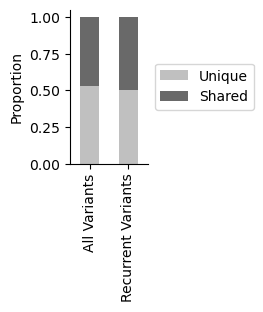

In [32]:
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
sharingBinary.drop(index='Unique Variants').plot(
    kind='bar',
    stacked=True,
    color=binaryPalette,
    legend=True,
    figsize=(1,2)
)
plt.legend(loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.ylabel('Proportion')
plt.tight_layout()
sns.despine()
#plt.savefig('plot_outputs/proportion_emVar_sharing_v2.pdf', dpi=300)

In [33]:
display(sharingBinary)

,Unique,Shared
All Variants,0.531057,0.468943
Unique Variants,0.532106,0.467894
Recurrent Variants,0.500000,0.500000


In [34]:
# calculate differences between categories - ie are recurrent variants more shared than unique variants
uniqueCount = pd.DataFrame(uniqueemVarsSummary.sum(numeric_only=True)[:7], columns=['Unique Variants'])
recurrentCount = pd.DataFrame(recurrentemVarsSummary.sum(numeric_only=True)[:7], columns=['Recurrent Variants'])
# merge dfs
mergeCount = uniqueCount.merge(recurrentCount, left_index=True, right_index=True)

In [35]:
# calculate the chi-square for the proportion of shared variants - all only
allEmVarChi2x2 = pd.DataFrame({
    0 : [mergeCount.loc['all', :].values[0], (mergeCount['Unique Variants'].sum() - mergeCount.loc['all', :][0])],
    1 : [mergeCount.loc['all', :].values[1], (mergeCount['Recurrent Variants'].sum() - mergeCount.loc['all', :][1])]
})
emVarShareChi2 = stats.chi2_contingency(allEmVarChi2x2)

/tmp/ipykernel_2337328/796677207.py:3: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  0 : [mergeCount.loc['all', :].values[0], (mergeCount['Unique Variants'].sum() - mergeCount.loc['all', :][0])],
/tmp/ipykernel_2337328/796677207.py:4: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  1 : [mergeCount.loc['all', :].values[1], (mergeCount['Recurrent Variants'].sum() - mergeCount.loc['all', :][1])]


In [36]:
emVarShareChi2

Chi2ContingencyResult(statistic=np.float64(9.246260871747975), pvalue=np.float64(0.0023597676026149003), dof=1, expected_freq=array([[10934.75987328,   369.24012672],
       [30288.24012672,  1022.75987328]]))

In [37]:
# calculate the chi-square for the proportion of shared variants - any sharing only
anyShareUnique = sum(mergeCount['Unique Variants'][3:])
anyShareRecurrent = sum(mergeCount['Recurrent Variants'][3:])
anyEmVarChi2x2 = pd.DataFrame({
    0 : [anyShareUnique, (mergeCount['Unique Variants'].sum() - anyShareUnique)],
    1 : [anyShareRecurrent, (mergeCount['Recurrent Variants'].sum() - anyShareRecurrent)]
})
emVarAnyShareChi2 = stats.chi2_contingency(anyEmVarChi2x2)

In [38]:
emVarAnyShareChi2

Chi2ContingencyResult(statistic=np.float64(5.445271463342468), pvalue=np.float64(0.019621365532356105), dof=1, expected_freq=array([[19331.23153819,   652.76846181],
       [21891.76846181,   739.23153819]]))

In [39]:
### emVars shared across >1 cell type, or all cell types are overrepresented in recurrent vs. private variants ###

In [40]:
# calculate the enrichment of recurrent over unique variants for each cell type matched by either tissue of origin or histology
# get counts for each each group
# recurrent
n_recurrent = len(cosmic_preds[cosmic_preds['recurrent'] == 1])
n_rec_emVar = len(cosmic_preds[(cosmic_preds['recurrent'] == 1) & (cosmic_preds['emvar_any'] == 1)])
# unique
n_unique = len(cosmic_preds[cosmic_preds['recurrent'] == 0])
n_uniq_emVar = len(cosmic_preds[(cosmic_preds['recurrent'] == 0) & (cosmic_preds['emvar_any'] == 1)])
# build 2x2 for computing OR
baseline2x2 = pd.DataFrame({
    0 : [n_rec_emVar, (n_recurrent - n_rec_emVar)],
    1 : [n_uniq_emVar, (n_unique - n_uniq_emVar)]
})
# compute OR and significance of recurrent vs unique emVar enrichment
recOR = stats.contingency.odds_ratio(baseline2x2)
rec95CI = recOR.confidence_interval(confidence_level=0.95)
recFisher = stats.fisher_exact(baseline2x2)
baselineTuple = (recOR, rec95CI, recFisher, baseline2x2)

In [41]:
# define function for building 2x2 table for comparing odds ratios of cell matched recurrent vs. unique
def cell_matched_or (
    predsDF,
    tissue_site_col,
    tissue_or_histology,
    cell_type):
    # subset the full df for the tissue/histology of interest
    subsetDF = predsDF[predsDF[tissue_site_col].isin(tissue_or_histology)].copy()
    # split that DF into unique and recurrent variant
    recurrentSubset = subsetDF[subsetDF['recurrent'] == 1].copy()
    uniqueSubset = subsetDF[subsetDF['recurrent'] == 0].copy()
    # get the numbers for building the 2x2
    # recurrent
    n_recurrent = len(recurrentSubset)
    n_recurrent_emVars = len(recurrentSubset[recurrentSubset[f'{cell_type.lower()}_emvar'] == 1])
    # unique
    n_unique = len(uniqueSubset)
    n_unique_emVars = len(uniqueSubset[uniqueSubset[f'{cell_type.lower()}_emvar'] == 1])
    # build 2x2
    twoBytwo = pd.DataFrame({
        0 : [n_recurrent_emVars, (n_recurrent - n_recurrent_emVars)],
        1 : [n_unique_emVars, (n_unique - n_unique_emVars)]
    })
    # get odds ratios, etc.
    or2return = stats.contingency.odds_ratio(twoBytwo)
    or95CI = or2return.confidence_interval(confidence_level=0.95)
    fisher = stats.fisher_exact(twoBytwo)
    # return everything as a tuple
    return (or2return, or95CI, fisher, twoBytwo)

In [42]:
# define function for calculating or, cis, fisher, and 2x2
def OR_function (recurrentSubset,
                 uniqueSubset,
                 emvar_col,
                 cell_type):
    if emvar_col != 'emvar_any':
        emvar_col = f'{cell_type.lower()}_{emvar_col}'
    else:
        emvar_col = 'emvar_any'
    # get the numbers for building the 2x2
    # recurrent
    n_recurrent = len(recurrentSubset)
    n_recurrent_emVars = len(recurrentSubset[recurrentSubset[emvar_col] == 1])
    # unique
    n_unique = len(uniqueSubset)
    n_unique_emVars = len(uniqueSubset[uniqueSubset[emvar_col] == 1])
    # build 2x2
    twoBytwo = pd.DataFrame({
        0 : [n_recurrent_emVars, (n_recurrent - n_recurrent_emVars)],
        1 : [n_unique_emVars, (n_unique - n_unique_emVars)]
    })
    # get odds ratios, etc.
    or2return = stats.contingency.odds_ratio(twoBytwo)
    or95CI = or2return.confidence_interval(confidence_level=0.95)
    fisher = stats.fisher_exact(twoBytwo)
    return (or2return, or95CI, fisher, twoBytwo)

In [43]:
# define function for building 2x2 table for comparing odds ratios of cell matched recurrent vs. unique
def cell_matched_or_specific (
    predsDF,
    tissue_site_col,
    tissue_or_histology,
    cell_type,
    emvar_col):
    # subset the full df for the tissue/histology of interest
    subsetDF = predsDF[predsDF[tissue_site_col].isin(tissue_or_histology)].copy()
    # split that DF into unique and recurrent variant
    recurrentSubset = subsetDF[subsetDF['recurrent'] == 1].copy()
    uniqueSubset = subsetDF[subsetDF['recurrent'] == 0].copy()
    # get info for desired input cell type
    targetOR = OR_function(
        recurrentSubset,
        uniqueSubset,
        emvar_col,
        cell_type
    )
    # get info for the OR for any emVar in that tissue
    targetOR_any = OR_function(
        recurrentSubset,
        uniqueSubset,
        'emvar_any',
        ''
    )
    # get info for the OR that an emVar is in that cell type but not ONLY in that cell type
    targetOR_nonSpecific = OR_function(
        recurrentSubset,
        uniqueSubset,
        'emvar',
        cell_type
    )
    # make a dictionary to return all ORs
    dict2return = {}
    allAnn = (',').join(tissue_or_histology)
    dict2return[allAnn] = {}
    dict2return[allAnn][cell_type] = targetOR
    dict2return[allAnn]['all'] = targetOR_any
    dict2return[allAnn][f'{cell_type.lower()} non-specific'] = targetOR_nonSpecific
    # calculate ORs for off target cell types
    if cell_type.lower() == 'k562':
        # compute odds ratios for off target cell types #
        # cell specific #
        # hepg2
        hepg2OR = OR_function(
            recurrentSubset,
            uniqueSubset,
            emvar_col,
            'hepg2'
        )
        dict2return[allAnn]['hepg2'] = hepg2OR
        # sknsh
        sknshOR = OR_function(
            recurrentSubset,
            uniqueSubset,
            emvar_col,
            'sknsh'
        )
        dict2return[allAnn]['sknsh'] = sknshOR
        # non cell specific #
        # hepg2
        hepg2OR_nonSpec = OR_function(
            recurrentSubset,
            uniqueSubset,
            'emvar',
            'hepg2'
        )
        dict2return[allAnn]['hepg2 non-specific'] = hepg2OR_nonSpec
        # sknsh
        sknshOR_nonSPec = OR_function(
            recurrentSubset,
            uniqueSubset,
            'emvar',
            'sknsh'
        )
        dict2return[allAnn]['sknsh non-specific'] = sknshOR_nonSPec
    if cell_type.lower() == 'hepg2':
        # compute odds ratios for off target cell types #
        # cell specific #
        # k562
        k562OR = OR_function(
            recurrentSubset,
            uniqueSubset,
            emvar_col,
            'k562'
        )
        dict2return[allAnn]['k562'] = k562OR
        # sknsh
        sknshOR = OR_function(
            recurrentSubset,
            uniqueSubset,
            emvar_col,
            'sknsh'
        )
        dict2return[allAnn]['sknsh'] = sknshOR
        # non cell specific #
        # k562
        k562OR_nonSpec = OR_function(
            recurrentSubset,
            uniqueSubset,
            'emvar',
            'k562'
        )
        dict2return[allAnn]['k562 non-specific'] = k562OR_nonSpec
        # sknsh
        sknshOR_nonSPec = OR_function(
            recurrentSubset,
            uniqueSubset,
            'emvar',
            'sknsh'
        )
        dict2return[allAnn]['sknsh non-specific'] = sknshOR_nonSPec
    if cell_type.lower() == 'sknsh':
        # compute odds ratios for off target cell types #
        # cell specific #
        # k562
        k562OR = OR_function(
            recurrentSubset,
            uniqueSubset,
            emvar_col,
            'k562'
        )
        dict2return[allAnn]['k562'] = k562OR
        # hepg2
        hepg2OR = OR_function(
            recurrentSubset,
            uniqueSubset,
            emvar_col,
            'hepg2'
        )
        dict2return[allAnn]['hepg2'] = hepg2OR
        # non cell specific
        # k562
        k562OR_nonSpec = OR_function(
            recurrentSubset,
            uniqueSubset,
            'emvar',
            'k562'
        )
        dict2return[allAnn]['k562 non-specific'] = k562OR_nonSpec
        # hepg2
        hepg2OR_nonSpec = OR_function(
            recurrentSubset,
            uniqueSubset,
            'emvar',
            'hepg2'
        )
        dict2return[allAnn]['hepg2 non-specific'] = hepg2OR_nonSpec
    return dict2return

In [44]:
# define a palette for plotting primary tissue-based odds ratios
primaryTissueORpalette = {
    'All Variants' : 'k',
    'K562 Matched' : '#00A79D',
    'HepG2 Matched' : '#FBB040',
    'SKNSH Matched' : '#ED1C24'
}

In [45]:
# calculate odds ratios using only predictions that are specific to a given cell type matched by primary tissue
# k562
k562_specific_OR_comps = cell_matched_or_specific(
    cosmic_preds,
    'primary_site',
    ['haematopoietic_and_lymphoid_tissue'],
    'k562',
    'emvar_only'
)
# hepg2
hepg2_specific_OR_comps = cell_matched_or_specific(
    cosmic_preds,
    'primary_site',
    ['liver'],
    'hepg2',
    'emvar_only'
)
# sknsh
sknsh_specific_OR_comps = cell_matched_or_specific(
    cosmic_preds,
    'primary_site',
    ['central_nervous_system'],
    'sknsh',
    'emvar_only'
)

In [46]:
DISPLAY_NAMES = {
    'all': 'All',
    'k562': 'K562',
    'hepg2': 'HepG2',
    'sknsh': 'SKNSH',
    'k562 non-specific': 'K562 Non-Specific',
    'hepg2 non-specific': 'HepG2 Non-Specific',
    'sknsh non-specific': 'SKNSH Non-Specific',
}

# fix order
CELL_TYPE_ORDER = ['all', 'k562 non-specific', 'hepg2 non-specific', 'sknsh non-specific', 'k562', 'hepg2', 'sknsh']

def results_dict_to_df(data):
    rows = []
    for match, cell_results in data.items():
        # keep only cell types present for this match, in the specified order
        ordered_keys = [k for k in CELL_TYPE_ORDER if k in cell_results]
        for cell_type in ordered_keys:
            odds_result, ci, sig_result = cell_results[cell_type][:3]
            rows.append({
                'Match': match,
                'Odds Ratio': odds_result.statistic,
                'Lower CI': ci.low,
                'Upper CI': ci.high,
                'Cell Type': DISPLAY_NAMES.get(cell_type, cell_type),
                'p-value': sig_result.pvalue,
            })
    return pd.DataFrame(rows)

In [47]:
# build DF for plotting
# make with only baseline to start
TissueOR_base = pd.DataFrame({
    'Match' : ['All Variants'],
    'Odds Ratio' : [baselineTuple[2][0]],
    'Lower CI' : [baselineTuple[1][0]],
    'Upper CI' : [baselineTuple[1][1]],
    'Cell Type' : ['All'],
    'p-value' : [baselineTuple[2][-1]]
})
TissueOR_df2plot = pd.concat([TissueOR_base, pd.concat([results_dict_to_df(i) for i in [k562_specific_OR_comps, hepg2_specific_OR_comps, sknsh_specific_OR_comps]])]).copy().reset_index(drop=True)
# add indexing for plot
TissueOR_df2plot.loc[:, 'x_index'] = [0,
                                      1,1,1,1,1,1,1,
                                      2,2,2,2,2,2,2,
                                      3,3,3,3,3,3,3]

In [48]:
# define a palette for plotting primary tissue-based odds ratios
plotPalette = {
    'All' : 'black',
    'K562' : '#00A79D',
    'K562 Non-Specific' : '#00A79D',
    'HepG2' : '#FBB040',
    'HepG2 Non-Specific' : '#FBB040',
    'SKNSH' : '#ED1C24',
    'SKNSH Non-Specific' : '#ED1C24'
}

In [55]:
TissueOR_df2plot

,Match,Odds Ratio,Lower CI,Upper CI,Cell Type,p-value,x_index
0,All Variants,1.336959,1.265646,1.411360,All,6.513069e-24,0
1,haematopoietic_and_lymphoid_tissue,1.199256,1.021679,1.399981,All,2.368844e-02,1
2,haematopoietic_and_lymphoid_tissue,1.203785,0.986035,1.457015,K562 Non-Specific,5.755129e-02,1
3,haematopoietic_and_lymphoid_tissue,1.072382,0.839542,1.351850,HepG2 Non-Specific,5.425950e-01,1
4,haematopoietic_and_lymphoid_tissue,1.057178,0.846150,1.306511,SKNSH Non-Specific,5.805423e-01,1
5,haematopoietic_and_lymphoid_tissue,1.456849,1.101619,1.894786,K562,7.020921e-03,1
6,haematopoietic_and_lymphoid_tissue,1.172667,0.596652,2.090740,HepG2,5.245364e-01,1
7,haematopoietic_and_lymphoid_tissue,1.265139,0.856281,1.808510,SKNSH,1.882328e-01,1
8,liver,1.624036,1.428067,1.839999,All,1.280430e-12,2
9,liver,1.760175,1.509034,2.041980,K562 Non-Specific,6.172550e-12,2


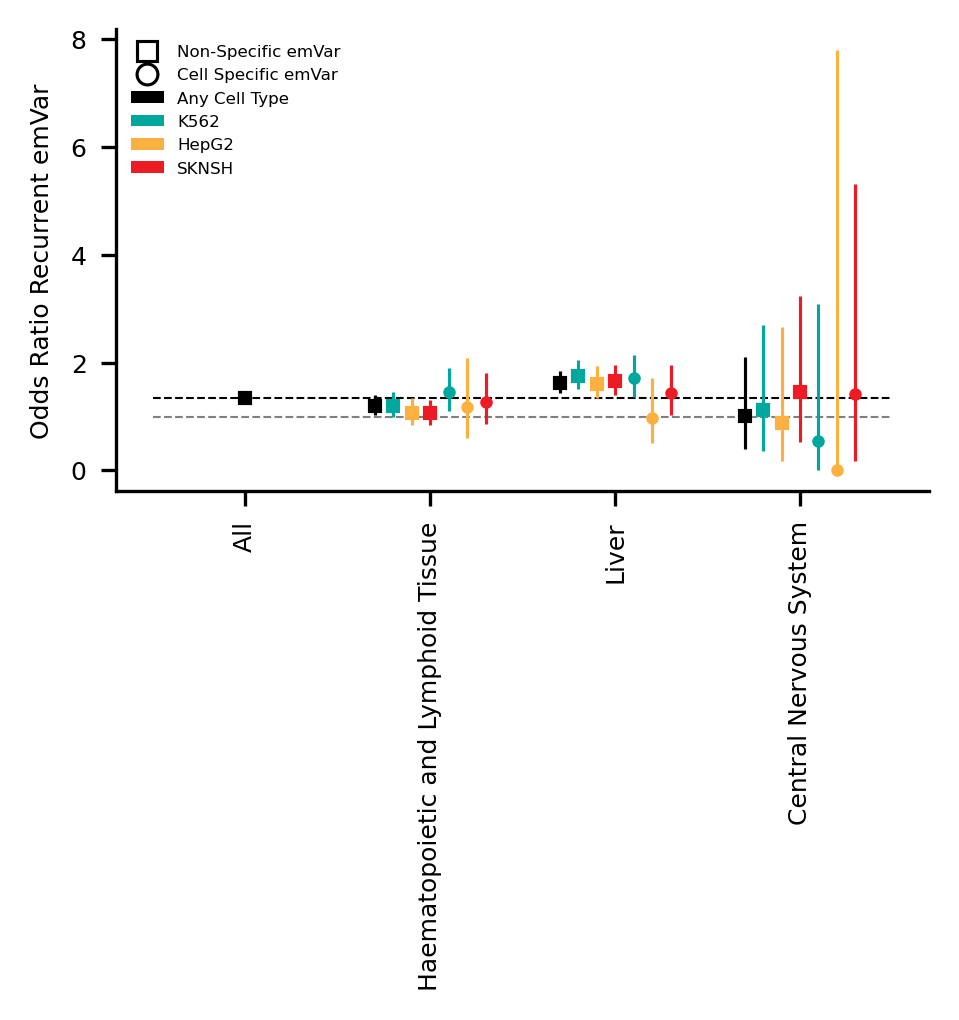

In [49]:
plt.figure(dpi=300, figsize = (3.5,2))
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.hlines(y=baselineTuple[2][0], xmin=-0.5, xmax=3.5, linestyles='dashed', color='k', linewidth=0.5)
plt.hlines(y=1, xmin=-0.5, xmax=3.5, linestyles='dashed', color='gray', linewidth=0.5)
plt.xticks([0,1,2,3], ['All', 'Haematopoietic and Lymphoid Tissue', 'Liver', 'Central Nervous System'], rotation = 90, fontsize=6)
# iterate through df for plotting
for i in range(len(TissueOR_df2plot)):
    # vectorize row
    row = TissueOR_df2plot.iloc[i, :].to_numpy()
    if i == 0 :
        x = row[-1]
        shape = 's'
        markerSize = 2.5
        #line='solid'
    elif i % 7 == 1:
        x = int(row[-1]) - 0.3
        shape = 's'
        markerSize = 2.5
        #line='dashed'
    elif i % 7 == 2:
        x = int(row[-1]) - 0.2
        shape = 's'
        markerSize = 2.5
        #line='dashed'
    elif i % 7 == 3:
        x = int(row[-1]) - 0.1
        shape = 's'
        markerSize = 2.5
        #line='dashed'
    elif i % 7 == 4:
        x = int(row[-1])
        shape = 's'
        markerSize = 2.5
        #line='solid'
    elif i % 7 == 5:
        x = int(row[-1]) + 0.1
        shape = '.'
        markerSize = 4
    elif i % 7 == 6:
        x = int(row[-1]) + 0.2
        shape = '.'
        markerSize = 4
    elif i % 7 == 0:
        x = int(row[-1]) + 0.3
        shape = '.'
        markerSize = 4
        #line='solid'
    # get the color for the plot
    color = plotPalette.get(row[-3])
    # plot OR
    plt.plot(
        x,
        row[1],
        marker=shape,
        markersize=markerSize,
        mec=color,
        color=color,
        linewidth=0
    )
    # plot CIs
    plt.vlines(x=x, ymin=row[2], ymax=row[3], linewidth=0.75, color=color)#, linestyles=line)
# build legend
legend_elements = [
    Line2D([0], [0], marker='s', color='w', markeredgecolor='k', markeredgewidth=0.75, label='Non-Specific emVar', markersize=5),
    Line2D([0], [0], marker='o', color='w', markeredgecolor='k', markeredgewidth=0.75, label='Cell Specific emVar', markersize=5),
    mpatches.Patch(facecolor='k', edgecolor='k', linewidth=0, label='Any Cell Type'),
    mpatches.Patch(facecolor='#00A79D', edgecolor='#00A79D', linewidth=0, label='K562'),
    mpatches.Patch(facecolor='#FBB040', edgecolor='#FBB040', linewidth=0, label='HepG2'),
    mpatches.Patch(facecolor='#ED1C24', edgecolor='#ED1C24', linewidth=0, label='SKNSH')
]
plt.legend(handles=legend_elements, loc='upper left', fontsize=4, frameon=False)
plt.ylabel('Odds Ratio Recurrent emVar', fontsize=6)
plt.yticks(fontsize=6)
sns.despine()
#plt.savefig('plot_outputs/primary_tissue_matched_variants_v3.pdf')

In [50]:
# define function for building 2x2 table for comparing odds ratios of cell matched recurrent vs. unique
def cell_matched_or_specific_custom_ann (
    predsDF,
    tissue_site_col,
    tissue_or_histology,
    cell_type,
    emvar_col,
    dictAnn):
    # subset the full df for the tissue/histology of interest
    subsetDF = predsDF[predsDF[tissue_site_col].isin(tissue_or_histology)].copy()
    # split that DF into unique and recurrent variant
    recurrentSubset = subsetDF[subsetDF['recurrent'] == 1].copy()
    uniqueSubset = subsetDF[subsetDF['recurrent'] == 0].copy()
    # get info for desired input cell type
    targetOR = OR_function(
        recurrentSubset,
        uniqueSubset,
        emvar_col,
        cell_type
    )
    # get info for the OR for any emVar in that tissue
    targetOR_any = OR_function(
        recurrentSubset,
        uniqueSubset,
        'emvar_any',
        ''
    )
    # get info for the OR that an emVar is in that cell type but not ONLY in that cell type
    targetOR_nonSpecific = OR_function(
        recurrentSubset,
        uniqueSubset,
        'emvar',
        cell_type
    )
    # make a dictionary to return all ORs
    dict2return = {}
    allAnn = dictAnn
    dict2return[allAnn] = {}
    dict2return[allAnn][cell_type] = targetOR
    dict2return[allAnn]['all'] = targetOR_any
    dict2return[allAnn][f'{cell_type.lower()} non-specific'] = targetOR_nonSpecific
    # calculate ORs for off target cell types
    if cell_type.lower() == 'k562':
        # compute odds ratios for off target cell types #
        # cell specific #
        # hepg2
        hepg2OR = OR_function(
            recurrentSubset,
            uniqueSubset,
            emvar_col,
            'hepg2'
        )
        dict2return[allAnn]['hepg2'] = hepg2OR
        # sknsh
        sknshOR = OR_function(
            recurrentSubset,
            uniqueSubset,
            emvar_col,
            'sknsh'
        )
        dict2return[allAnn]['sknsh'] = sknshOR
        # non cell specific #
        # hepg2
        hepg2OR_nonSpec = OR_function(
            recurrentSubset,
            uniqueSubset,
            'emvar',
            'hepg2'
        )
        dict2return[allAnn]['hepg2 non-specific'] = hepg2OR_nonSpec
        # sknsh
        sknshOR_nonSPec = OR_function(
            recurrentSubset,
            uniqueSubset,
            'emvar',
            'sknsh'
        )
        dict2return[allAnn]['sknsh non-specific'] = sknshOR_nonSPec
    if cell_type.lower() == 'hepg2':
        # compute odds ratios for off target cell types #
        # cell specific #
        # k562
        k562OR = OR_function(
            recurrentSubset,
            uniqueSubset,
            emvar_col,
            'k562'
        )
        dict2return[allAnn]['k562'] = k562OR
        # sknsh
        sknshOR = OR_function(
            recurrentSubset,
            uniqueSubset,
            emvar_col,
            'sknsh'
        )
        dict2return[allAnn]['sknsh'] = sknshOR
        # non cell specific #
        # k562
        k562OR_nonSpec = OR_function(
            recurrentSubset,
            uniqueSubset,
            'emvar',
            'k562'
        )
        dict2return[allAnn]['k562 non-specific'] = k562OR_nonSpec
        # sknsh
        sknshOR_nonSPec = OR_function(
            recurrentSubset,
            uniqueSubset,
            'emvar',
            'sknsh'
        )
        dict2return[allAnn]['sknsh non-specific'] = sknshOR_nonSPec
    if cell_type.lower() == 'sknsh':
        # compute odds ratios for off target cell types #
        # cell specific #
        # k562
        k562OR = OR_function(
            recurrentSubset,
            uniqueSubset,
            emvar_col,
            'k562'
        )
        dict2return[allAnn]['k562'] = k562OR
        # hepg2
        hepg2OR = OR_function(
            recurrentSubset,
            uniqueSubset,
            emvar_col,
            'hepg2'
        )
        dict2return[allAnn]['hepg2'] = hepg2OR
        # non cell specific
        # k562
        k562OR_nonSpec = OR_function(
            recurrentSubset,
            uniqueSubset,
            'emvar',
            'k562'
        )
        dict2return[allAnn]['k562 non-specific'] = k562OR_nonSpec
        # hepg2
        hepg2OR_nonSpec = OR_function(
            recurrentSubset,
            uniqueSubset,
            'emvar',
            'hepg2'
        )
        dict2return[allAnn]['hepg2 non-specific'] = hepg2OR_nonSpec
        
    return dict2return

In [51]:
# calculate odds ratios using only predictions that are specific to a given cell type matched by histology
# k562
k562_specific_OR_hist = cell_matched_or_specific_custom_ann(
    cosmic_preds,
    'histology_subtype_1',
    ['acute_myeloid_leukaemia', 'acute_myeloid_leukaemia_therapy_related', 'chronic_myeloid_leukaemia'],
    'k562',
    'emvar_only',
    'Myeloid Leukaemia'
)
# hepg2
hepg2_specific_OR_hist = cell_matched_or_specific_custom_ann(
    cosmic_preds,
    'histology_subtype_1',
    ['hepatocellular_carcinoma'],
    'hepg2',
    'emvar_only',
    'Hepatocellular Carcinoma'
)
# sknsh
sknsh_specific_OR_hist = cell_matched_or_specific_custom_ann(
    cosmic_preds,
    'primary_histology',
    [i for i in cosmic_preds['primary_histology'] if 'neuro' in i],
    'sknsh',
    'emvar_only',
    'Contains Neuro'
)

In [52]:
# build DF for plotting
# make with only baseline to start
HistologyOR_base = pd.DataFrame({
    'Match' : ['All Variants'],
    'Odds Ratio' : [baselineTuple[2][0]],
    'Lower CI' : [baselineTuple[1][0]],
    'Upper CI' : [baselineTuple[1][1]],
    'Cell Type' : ['All'],
    'p-value' : [baselineTuple[2][-1]]
})
HistOR_df2plot = pd.concat([HistologyOR_base, pd.concat([results_dict_to_df(i) for i in [k562_specific_OR_hist, hepg2_specific_OR_hist, sknsh_specific_OR_hist]])]).copy().reset_index(drop=True)
# add indexing for plot
HistOR_df2plot.loc[:, 'x_index'] = [0,
                                      1,1,1,1,1,1,1,
                                      2,2,2,2,2,2,2,
                                      3,3,3,3,3,3,3]

In [53]:
plotPalette = {
    'All' : 'black',
    'K562' : '#00A79D',
    'K562 Non-Specific' : '#00A79D',
    'HepG2' : '#FBB040',
    'HepG2 Non-Specific' : '#FBB040',
    'SKNSH' : '#ED1C24',
    'SKNSH Non-Specific' : '#ED1C24'
}

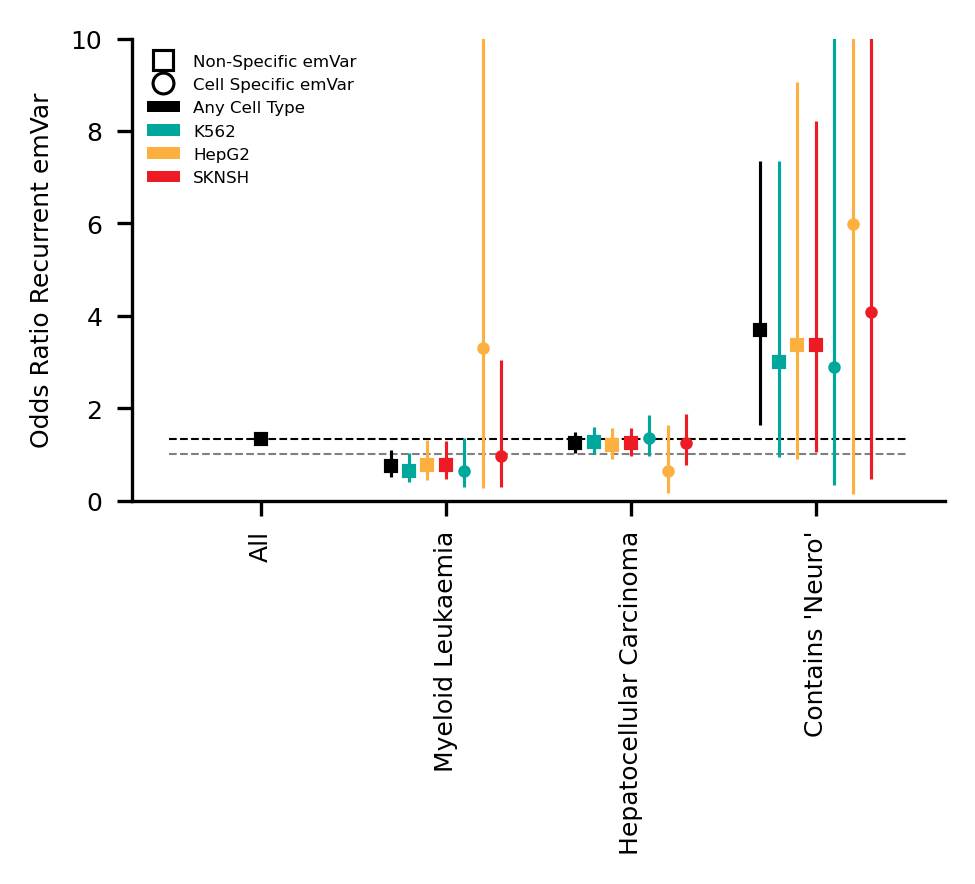

In [54]:
plt.figure(dpi=300, figsize = (3.5,2))
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42
plt.hlines(y=baselineTuple[2][0], xmin=-0.5, xmax=3.5, linestyles='dashed', color='k', linewidth=0.5)
plt.hlines(y=1, xmin=-0.5, xmax=3.5, linestyles='dashed', color='gray', linewidth=0.5)
plt.xticks([0,1,2,3], ['All', 'Myeloid Leukaemia', 'Hepatocellular Carcinoma', 'Contains \'Neuro\''], rotation = 90, fontsize=6)
# iterate through df for plotting
for i in range(len(HistOR_df2plot)):
    # vectorize row
    row = HistOR_df2plot.iloc[i, :].to_numpy()
    if i == 0 :
        x = row[-1]
        shape = 's'
        markerSize = 2.5
        #line='solid'
    elif i % 7 == 1:
        x = int(row[-1]) - 0.3
        shape = 's'
        markerSize = 2.5
        #line='dashed'
    elif i % 7 == 2:
        x = int(row[-1]) - 0.2
        shape = 's'
        markerSize = 2.5
        #line='dashed'
    elif i % 7 == 3:
        x = int(row[-1]) - 0.1
        shape = 's'
        markerSize = 2.5
        #line='dashed'
    elif i % 7 == 4:
        x = int(row[-1])
        shape = 's'
        markerSize = 2.5
        #line='solid'
    elif i % 7 == 5:
        x = int(row[-1]) + 0.1
        shape = '.'
        markerSize = 4
    elif i % 7 == 6:
        x = int(row[-1]) + 0.2
        shape = '.'
        markerSize = 4
    elif i % 7 == 0:
        x = int(row[-1]) + 0.3
        shape = '.'
        markerSize = 4
        #line='solid'
    # get the color for the plot
    color = plotPalette.get(row[-3])
    # plot OR
    plt.plot(
        x,
        row[1],
        marker=shape,
        markersize=markerSize,
        mec=color,
        color=color,
        linewidth=0
    )
    # plot CIs
    plt.vlines(x=x, ymin=row[2], ymax=row[3], linewidth=0.75, color=color)#, linestyles=line)
# build legend
legend_elements = [
    Line2D([0], [0], marker='s', color='w', markeredgecolor='k', markeredgewidth=0.75, label='Non-Specific emVar', markersize=5),
    Line2D([0], [0], marker='o', color='w', markeredgecolor='k', markeredgewidth=0.75, label='Cell Specific emVar', markersize=5),
    mpatches.Patch(facecolor='k', edgecolor='k', linewidth=0, label='Any Cell Type'),
    mpatches.Patch(facecolor='#00A79D', edgecolor='#00A79D', linewidth=0, label='K562'),
    mpatches.Patch(facecolor='#FBB040', edgecolor='#FBB040', linewidth=0, label='HepG2'),
    mpatches.Patch(facecolor='#ED1C24', edgecolor='#ED1C24', linewidth=0, label='SKNSH')
]
plt.legend(handles=legend_elements, loc='upper left', fontsize=4, frameon=False)
plt.ylabel('Odds Ratio Recurrent emVar', fontsize=6)
plt.ylim(0,10)
plt.yticks(fontsize=6)
sns.despine()
#plt.savefig('plot_outputs/primary_histology_matched_variants_v3.pdf')

In [56]:
HistOR_df2plot

,Match,Odds Ratio,Lower CI,Upper CI,Cell Type,p-value,x_index
0,All Variants,1.336959,1.265646,1.411360,All,6.513069e-24,0
1,Myeloid Leukaemia,0.750977,0.506598,1.105204,All,1.360956e-01,1
2,Myeloid Leukaemia,0.648610,0.403693,1.026978,K562 Non-Specific,6.346771e-02,1
3,Myeloid Leukaemia,0.772359,0.447515,1.315047,HepG2 Non-Specific,3.742764e-01,1
4,Myeloid Leukaemia,0.777208,0.464126,1.286191,SKNSH Non-Specific,3.356103e-01,1
5,Myeloid Leukaemia,0.649692,0.299900,1.351665,K562,2.376717e-01,1
6,Myeloid Leukaemia,3.310584,0.265605,173.904793,HepG2,3.522417e-01,1
7,Myeloid Leukaemia,0.964820,0.297327,3.050204,SKNSH,1.000000e+00,1
8,Hepatocellular Carcinoma,1.241192,1.025896,1.489607,All,2.390144e-02,2
9,Hepatocellular Carcinoma,1.278432,1.011819,1.595511,K562 Non-Specific,3.650296e-02,2
